In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"

# elif "augustiner" in hostname: 
#     DATA_DIR = "/home/franzihe/Data/"
#     FIG_DIR = "/home/franzihe/Documents/Figures/mrr_reflectivity/"

if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)
# sys.path.append(os.path.join(UTILS_DIR, 'pymascdb'))
os.chdir(os.path.join(UTILS_DIR, 'pymascdb'))

# # make figure directory to put in reflectivity processed data
# try:
#     new_dir = pathlib.Path(FIG_DIR)
#     new_dir.mkdir(parents=True, exist_ok=True)
# except OSError:
#     pass

mimi.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

In [3]:
from imports_mascdb import (masc, np, pd, cm, xr, glob, set_context, plt, mdates, time, datetime)

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
masc_in = os.path.join(INPUT_DATA_DIR, 'MASC_DB')
### Create MASC_DB instance 
mascdb = masc.MASC_DB(dir_path=masc_in)

In [6]:
campaign23 = mascdb.select_campaign('Norway-2023')


In [7]:
cam1 = campaign23.cam1.copy()
# 2) ensure datetime column is datetime dtype
cam1['datetime'] = pd.to_datetime(cam1['datetime'])
# 3) boolean mask for the desired interval
mask = (
    (cam1['datetime'] >= "2023-03-09 00:00") &
    (cam1['datetime'] <= "2023-03-09 06:00")
)

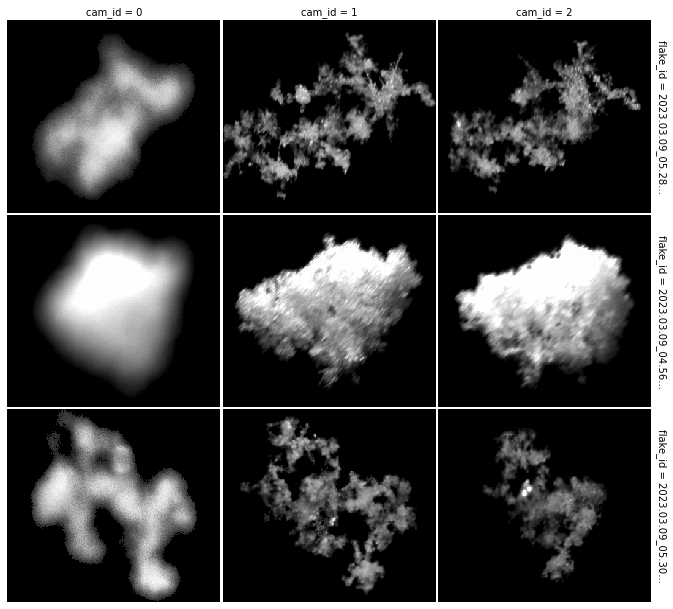

In [8]:
if cam1.index.name == "flake_id":
    flake_ids = cam1.index[mask].tolist()
elif 'flake_id' in cam1.columns:
    flake_ids = cam1.loc[mask, 'flake_id'].tolist()
else:
    raise RuntimeError("Can't find flake_id as index or column in cam1")

if len(flake_ids) == 0:
    print("No flakes found in that time window.")
else:
    # 5) subset the MASC_DB using sel
    subset_db = campaign23.sel(flake_ids=flake_ids)   # returns a MASC_DB instance. 

    # 6) then use your arrange / plot pipeline on the subset
    largeD = subset_db.arrange('cam1.Dmax', decreasing=True)   
    largeD.plot_triplets(n_triplets=3)                         # plot_triplets 

plt.savefig(os.path.join(FIG_DIR, 'triplet_img', '2023-03-09.png'), format='png', bbox_inches='tight', dpi=300) #transparent=True,